In [12]:

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, SimpleRNN, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    accuracy_score
)

tf.keras.utils.set_random_seed(42)

print("All libraries imported successfully!")
print("TensorFlow version:", tf.__version__)


All libraries imported successfully!
TensorFlow version: 2.21.0


In [13]:

from tensorflow.keras.datasets import fashion_mnist

(X_train_full, y_train_full), (X_test, y_test) = (
    fashion_mnist.load_data()
)

print("Dataset loaded successfully!")
print("Original training images:", X_train_full.shape)
print("Testing images:", X_test.shape)
print("Training labels:", y_train_full.shape)
print("Testing labels:", y_test.shape)


29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Dataset loaded successfully!
Original training images: (60000, 28, 28)
Testing images: (10000, 28, 28)
Training labels: (60000,)
Testing labels: (10000,)


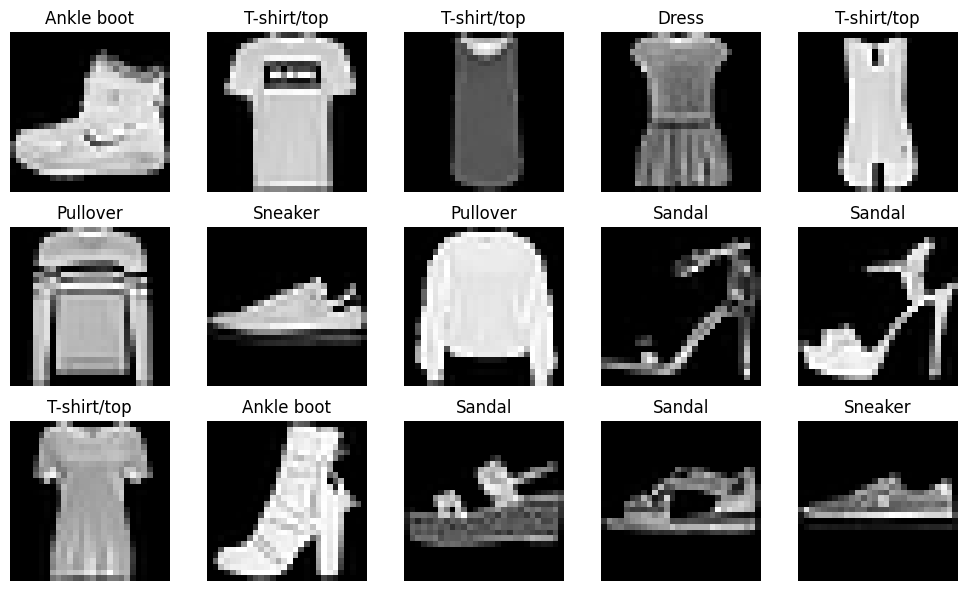

Total classes: 10


In [14]:

class_names = [
    "T-shirt/top",
    "Trouser",
    "Pullover",
    "Dress",
    "Coat",
    "Sandal",
    "Shirt",
    "Sneaker",
    "Bag",
    "Ankle boot"
]

plt.figure(figsize=(10, 6))

for i in range(15):
    plt.subplot(3, 5, i + 1)
    plt.imshow(X_train_full[i], cmap="gray")
    plt.title(class_names[y_train_full[i]])
    plt.axis("off")

plt.tight_layout()
plt.show()

print("Total classes:", len(class_names))


In [15]:

# Normalize pixel values from 0-255 to 0-1
X_train_full = X_train_full.astype("float32") / 255.0
X_test = X_test.astype("float32") / 255.0

# Each image becomes a sequence of 28 time steps
# Every time step contains 28 pixel values

print("Training data shape:", X_train_full.shape)
print("Testing data shape:", X_test.shape)
print("Minimum pixel value:", X_train_full.min())
print("Maximum pixel value:", X_train_full.max())


Training data shape: (60000, 28, 28)
Testing data shape: (10000, 28, 28)
Minimum pixel value: 0.0
Maximum pixel value: 1.0


In [16]:

from sklearn.model_selection import train_test_split

X_train, X_val, y_train, y_val = train_test_split(
    X_train_full,
    y_train_full,
    test_size=0.10,
    random_state=42,
    stratify=y_train_full
)

print("Training samples:", len(X_train))
print("Validation samples:", len(X_val))
print("Testing samples:", len(X_test))

print("RNN input shape:", X_train.shape[1:])


Training samples: 54000
Validation samples: 6000
Testing samples: 10000
RNN input shape: (28, 28)


In [17]:

tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(42)

model = Sequential([
    Input(shape=(28, 28)),

    SimpleRNN(128, return_sequences=True, activation="tanh"),
    Dropout(0.2),

    SimpleRNN(64, activation="tanh"),
    Dropout(0.3),

    Dense(64, activation="relu"),
    Dropout(0.2),

    Dense(10, activation="softmax")
])

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ simple_rnn (SimpleRNN)          │ (None, 28, 128)        │        20,096 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 28, 128)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn_1 (SimpleRNN)        │ (None, 64)             │        12,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 37,258 (145.54 KB)

 Trainable params: 37,258 (145.54 KB)

 Non-trainable params: 0 (0.00 B)

In [18]:

early_stop = EarlyStopping(
    monitor="val_loss",
    patience=4,
    restore_best_weights=True,
    verbose=1
)

reduce_lr = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=2,
    min_lr=0.00001,
    verbose=1
)

history = model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=20,
    batch_size=128,
    callbacks=[early_stop, reduce_lr],
    verbose=1
)

print("Simple RNN training completed successfully!")


Epoch 1/20
422/422 ━━━━━━━━━━━━━━━━━━━━ 14s 20ms/step - accuracy: 0.6742 - loss: 0.8904 - val_accuracy: 0.7923 - val_loss: 0.5723 - learning_rate: 0.0010
Epoch 2/20
422/422 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - accuracy: 0.7894 - loss: 0.6044 - val_accuracy: 0.8172 - val_loss: 0.5181 - learning_rate: 0.0010
Epoch 3/20
422/422 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.8132 - loss: 0.5452 - val_accuracy: 0.8317 - val_loss: 0.4907 - learning_rate: 0.0010
Epoch 4/20
422/422 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.8224 - loss: 0.5134 - val_accuracy: 0.8317 - val_loss: 0.4749 - learning_rate: 0.0010
Epoch 5/20
422/422 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.8336 - loss: 0.4796 - val_accuracy: 0.8493 - val_loss: 0.4174 - learning_rate: 0.0010
Epoch 6/20
422/422 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - accuracy: 0.8374 - loss: 0.4715 - val_accuracy: 0.8505 - val_loss: 0.4070 - learning_rate: 0.0010
Epoch 7/20
422/422 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.8384 - loss: 0.4642 

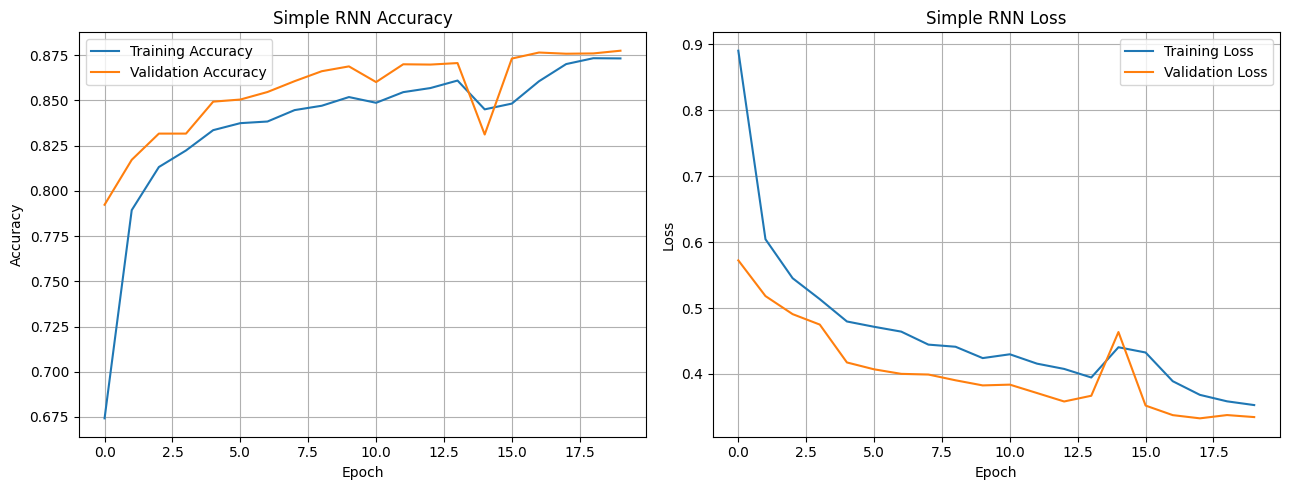

In [19]:

plt.figure(figsize=(13, 5))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.title("Simple RNN Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("Simple RNN Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()


In [20]:

test_loss, test_accuracy = model.evaluate(
    X_test, y_test, verbose=1
)

y_prob = model.predict(X_test, batch_size=256, verbose=1)
y_pred = np.argmax(y_prob, axis=1)

print(f"\nTest Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy * 100:.2f}%")


313/313 ━━━━━━━━━━━━━━━━━━━━ 4s 7ms/step - accuracy: 0.8660 - loss: 0.3660
40/40 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step

Test Loss: 0.3660
Test Accuracy: 86.60%


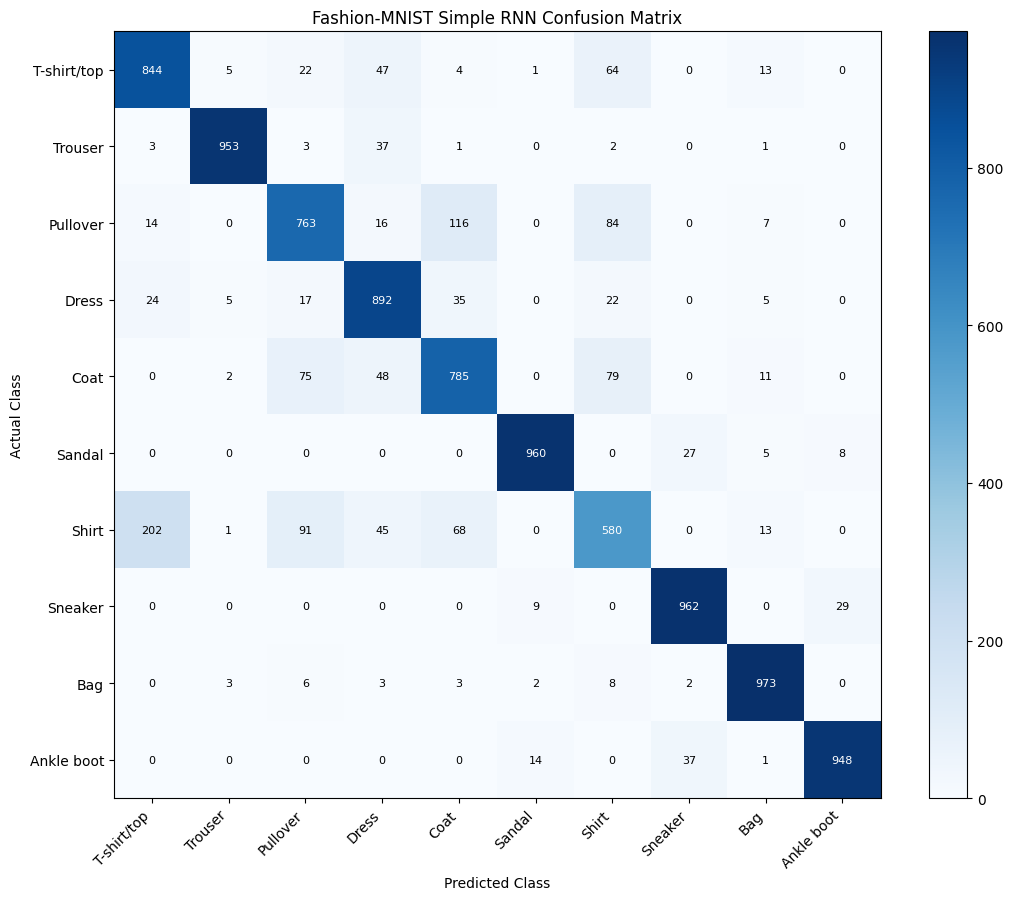

In [21]:

cm = confusion_matrix(
    y_test,
    y_pred,
    labels=np.arange(10)
)

plt.figure(figsize=(11, 9))
plt.imshow(cm, interpolation="nearest", cmap="Blues")
plt.title("Fashion-MNIST Simple RNN Confusion Matrix")
plt.colorbar()

ticks = np.arange(10)
plt.xticks(ticks, class_names, rotation=45, ha="right")
plt.yticks(ticks, class_names)
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")

threshold = cm.max() / 2

for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        plt.text(
            j, i, str(cm[i, j]),
            ha="center", va="center",
            color="white" if cm[i, j] > threshold else "black",
            fontsize=8
        )

plt.tight_layout()
plt.show()


In [22]:

print(classification_report(
    y_test,
    y_pred,
    labels=np.arange(10),
    target_names=class_names,
    digits=4,
    zero_division=0
))


              precision    recall  f1-score   support

 T-shirt/top     0.7764    0.8440    0.8088      1000
     Trouser     0.9835    0.9530    0.9680      1000
    Pullover     0.7810    0.7630    0.7719      1000
       Dress     0.8199    0.8920    0.8544      1000
        Coat     0.7757    0.7850    0.7803      1000
      Sandal     0.9736    0.9600    0.9668      1000
       Shirt     0.6913    0.5800    0.6308      1000
     Sneaker     0.9358    0.9620    0.9487      1000
         Bag     0.9456    0.9730    0.9591      1000
  Ankle boot     0.9624    0.9480    0.9552      1000

    accuracy                         0.8660     10000
   macro avg     0.8645    0.8660    0.8644     10000
weighted avg     0.8645    0.8660    0.8644     10000



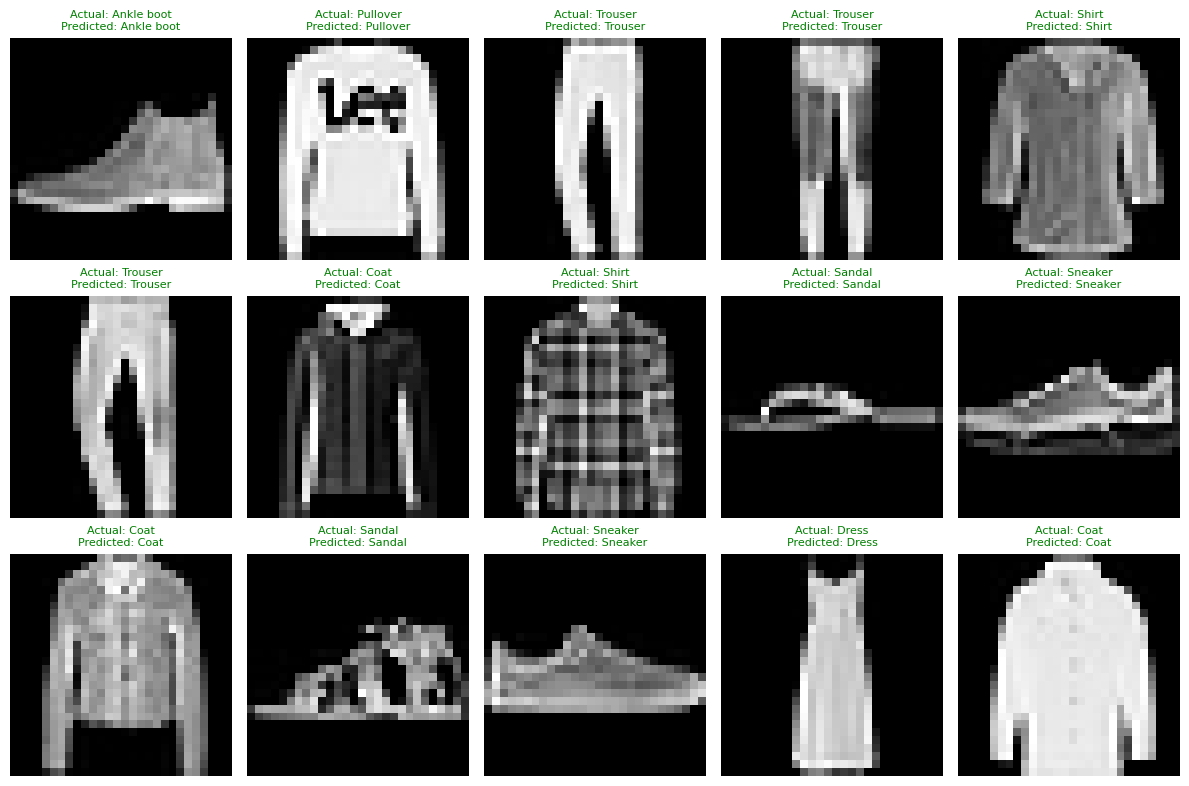

In [23]:

plt.figure(figsize=(12, 8))

for i in range(15):
    plt.subplot(3, 5, i + 1)
    plt.imshow(X_test[i], cmap="gray")

    actual = class_names[y_test[i]]
    predicted = class_names[y_pred[i]]

    color = "green" if y_test[i] == y_pred[i] else "red"

    plt.title(
        f"Actual: {actual}\nPredicted: {predicted}",
        color=color,
        fontsize=8
    )
    plt.axis("off")

plt.tight_layout()
plt.show()


In [24]:

results = pd.DataFrame({
    "Actual_Label": [class_names[i] for i in y_test],
    "Predicted_Label": [class_names[i] for i in y_pred],
    "Actual_ID": y_test,
    "Predicted_ID": y_pred,
    "Correct": y_test == y_pred,
    "Confidence_Percent": np.max(y_prob, axis=1) * 100
})

results.to_csv("fashion_mnist_rnn_predictions.csv", index=False)

print("Predictions CSV created successfully!")
display(results.head(10))

from google.colab import files
files.download("fashion_mnist_rnn_predictions.csv")


Predictions CSV created successfully!


,Actual_Label,Predicted_Label,Actual_ID,Predicted_ID,Correct,Confidence_Percent
0,Ankle boot,Ankle boot,9,9,True,99.501389
1,Pullover,Pullover,2,2,True,94.238426
2,Trouser,Trouser,1,1,True,99.968979
3,Trouser,Trouser,1,1,True,99.975105
4,Shirt,Shirt,6,6,True,76.665276
5,Trouser,Trouser,1,1,True,99.951111
6,Coat,Coat,4,4,True,93.681976
7,Shirt,Shirt,6,6,True,96.092987
8,Sandal,Sandal,5,5,True,99.837242
9,Sneaker,Sneaker,7,7,True,99.483421


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [25]:

model.save("fashion_mnist_simple_rnn.keras")

print("Trained RNN model saved successfully!")

files.download("fashion_mnist_simple_rnn.keras")


Trained RNN model saved successfully!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [26]:

final_accuracy = accuracy_score(y_test, y_pred)

correct_predictions = int(np.sum(y_test == y_pred))
total_predictions = len(y_test)

print("=" * 55)
print(" FASHION-MNIST IMAGE CLASSIFICATION USING SIMPLE RNN")
print("=" * 55)

print("Dataset: Fashion-MNIST")
print("Model: Simple Recurrent Neural Network")
print("Image Size: 28 x 28 pixels")
print("Number of Classes:", len(class_names))
print("Training Samples:", len(X_train))
print("Validation Samples:", len(X_val))
print("Testing Samples:", total_predictions)

print("-" * 55)
print(f"Test Accuracy: {final_accuracy * 100:.2f}%")
print(f"Test Loss: {test_loss:.4f}")
print(f"Correct Predictions: {correct_predictions}/{total_predictions}")
print("-" * 55)

print("Output files:")
print("1. fashion_mnist_rnn_predictions.csv")
print("2. fashion_mnist_simple_rnn.keras")

print("=" * 55)
print("PROJECT COMPLETED SUCCESSFULLY!")
print("=" * 55)


 FASHION-MNIST IMAGE CLASSIFICATION USING SIMPLE RNN
Dataset: Fashion-MNIST
Model: Simple Recurrent Neural Network
Image Size: 28 x 28 pixels
Number of Classes: 10
Training Samples: 54000
Validation Samples: 6000
Testing Samples: 10000
-------------------------------------------------------
Test Accuracy: 86.60%
Test Loss: 0.3660
Correct Predictions: 8660/10000
-------------------------------------------------------
Output files:
1. fashion_mnist_rnn_predictions.csv
2. fashion_mnist_simple_rnn.keras
PROJECT COMPLETED SUCCESSFULLY!
